모델 보완: 룰이 놓친 사기에 대한 LightGBM 보완 효과 측정<p>
언더샘플링은 train에만 적용, 컷오프는 valid에서 결정, test는 최종 1회 평가

In [1]:
import pandas as pd
import numpy as np
import joblib 
import warnings
warnings.filterwarnings("ignore")
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


In [2]:
base = pd.read_parquet("../data/processed/base.parquet")

In [3]:
train = base[base["month"] <= 4]
valid = base[base["month"] == 5]
test = base[base["month"] >= 6]

In [4]:
sentinel_cols = ["prev_address_months_count", "current_address_months_count",
                 "bank_months_count", "session_length_in_minutes",
                 "device_distinct_emails_8w"]

train[sentinel_cols].min()

prev_address_months_count      -1.0
current_address_months_count   -1.0
bank_months_count              -1.0
session_length_in_minutes      -1.0
device_distinct_emails_8w      -1.0
dtype: float64

In [5]:
cat_cols = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
drop_cols = ["fraud_bool", "month", "intended_balcon_amount"]

cat_types = {c: pd.CategoricalDtype(sorted(train[c].unique())) for c in cat_cols}


def make_X(df):
    X = df.drop(columns=drop_cols).copy()
    for c in sentinel_cols:
        X[c] = X[c].where(X[c] >= 0)
    for c in cat_cols:
        X[c] = X[c].astype(cat_types[c])
    return X


X_train, y_train = make_X(train), train["fraud_bool"]
X_valid, y_valid = make_X(valid), valid["fraud_bool"]

In [6]:
rules = {
    "고액 한도": lambda d: d["proposed_credit_limit"] >= 1900,
    "주거 BA": lambda d: d["housing_status"] == "BA",
    "windows": lambda d: d["device_os"] == "windows",
    "이름메일 유사도 낮음": lambda d: d["name_email_similarity"] < 0.18,
    "생년월일 메일 적음": lambda d: d["date_of_birth_distinct_emails_4w"] <= 4,
    "지점 방문 적음": lambda d: d["bank_branch_count_8w"] <= 1,
}


def eval_rule(df, flag):
    y = df["fraud_bool"] == 1
    old = df["customer_age"] >= 50
    tp = (flag & y).sum()
    fp = (flag & ~y).sum()
    return pd.Series({
        "flag_rate": flag.mean(),
        "precision": tp / flag.sum(),
        "recall": tp / y.sum(),
        "lift": (tp / flag.sum()) / y.mean(),
        "fp_per_1000": fp / len(df) * 1000,
        "fpr_50plus": (flag & ~y & old).sum() / (~y & old).sum(),
        "fpr_under50": (flag & ~y & ~old).sum() / (~y & ~old).sum(),
    })


def recall_at_rate(y, p, rate):
    cut = np.quantile(p, 1 - rate)
    return ((p >= cut) & (y.values == 1)).sum() / y.sum()

In [7]:
def fit_lgbm(X, y, neg_frac, seed=42):
    rng = np.random.RandomState(seed)
    keep = (y.values == 1) | (rng.rand(len(y)) < neg_frac)
    model = lgb.LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=seed,
        n_jobs=-1,
        verbose=-1,
    )
    model.fit(
        X[keep], y[keep],
        eval_set=[(X_valid, y_valid)],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model

In [8]:
hits_v = pd.concat({k: f(valid) for k, f in rules.items()}, axis=1).sum(axis=1)
rate_3 = (hits_v >= 3).mean()
rate_2 = (hits_v >= 2).mean()

models, val_rows = {}, {}
for frac in [1.0, 0.3, 0.1]:
    m = fit_lgbm(X_train, y_train, frac)
    p = m.predict_proba(X_valid)[:, 1]
    models[frac] = m
    val_rows[frac] = {
        "best_iter": m.best_iteration_,
        "pr_auc": average_precision_score(y_valid, p),
        "roc_auc": roc_auc_score(y_valid, p),
        "recall_3개이상_비율": recall_at_rate(y_valid, p, rate_3),
        "recall_2개이상_비율": recall_at_rate(y_valid, p, rate_2),
    }

pd.DataFrame(val_rows).T.round(4)

,best_iter,pr_auc,roc_auc,recall_3개이상_비율,recall_2개이상_비율
1.0,208.0,0.1913,0.8965,0.5826,0.8802
0.3,171.0,0.1911,0.8955,0.5918,0.8802
0.1,142.0,0.1932,0.8957,0.5918,0.8795


In [9]:
best_frac = max(val_rows, key=lambda k: val_rows[k]["pr_auc"])
model = models[best_frac]
p_valid = model.predict_proba(X_valid)[:, 1]

ref_v = {"3개 이상": hits_v >= 3, "2개 이상": hits_v >= 2}
cutoffs = {k: np.quantile(p_valid, 1 - flag.mean()) for k, flag in ref_v.items()}

best_frac, cutoffs

(0.1, {'3개 이상': 0.20079123876974395, '2개 이상': 0.050123525616479155})

In [10]:
rows = {}
for k, flag in ref_v.items():
    rows[f"룰 {k}"] = eval_rule(valid, flag)
    rows[f"모델 ({k} 룰과 동일 비율)"] = eval_rule(valid, pd.Series(p_valid >= cutoffs[k], index=valid.index))

pd.DataFrame(rows).T.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
룰 3개 이상,0.0698,0.0706,0.4167,5.9737,64.8324,0.1557,0.0469
모델 (3개 이상 룰과 동일 비율),0.0698,0.1003,0.5918,8.4830,62.7624,0.1349,0.0487
룰 2개 이상,0.2741,0.0313,0.7264,2.6499,265.5481,0.4528,0.2306
모델 (2개 이상 룰과 동일 비율),0.2741,0.0379,0.8795,3.2083,263.7379,0.4377,0.2315


In [11]:
X_test, y_test = make_X(test), test["fraud_bool"]
p_test = model.predict_proba(X_test)[:, 1]

hits_t = pd.concat({k: f(test) for k, f in rules.items()}, axis=1).sum(axis=1)
ref_t = {"3개 이상": hits_t >= 3, "2개 이상": hits_t >= 2}

rows = {}
for k, flag in ref_t.items():
    rows[f"룰 {k}"] = eval_rule(test, flag)
    rows[f"모델 (valid 컷오프, {k})"] = eval_rule(test, pd.Series(p_test >= cutoffs[k], index=test.index))

test_cmp = pd.DataFrame(rows).T
test_cmp.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
룰 3개 이상,0.0947,0.0679,0.4583,4.8397,88.2636,0.2032,0.0675
"모델 (valid 컷오프, 3개 이상)",0.0834,0.1064,0.6324,7.5798,74.5521,0.1645,0.0584
룰 2개 이상,0.3276,0.0332,0.7755,2.3676,316.6806,0.5298,0.2808
"모델 (valid 컷오프, 2개 이상)",0.3008,0.0418,0.8958,2.9780,288.2187,0.4780,0.2564


In [12]:
average_precision_score(y_test, p_test), roc_auc_score(y_test, p_test)

(0.19481945913828339, 0.8930558048035493)

In [13]:
rows = {}
for k, flag in ref_t.items():
    cut = np.quantile(p_test, 1 - flag.mean())
    rows[f"룰 {k}"] = eval_rule(test, flag)
    rows[f"모델 (test {k} 룰과 동일 비율)"] = eval_rule(test, pd.Series(p_test >= cut, index=test.index))

pd.DataFrame(rows).T.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
룰 3개 이상,0.0947,0.0679,0.4583,4.8397,88.2636,0.2032,0.0675
모델 (test 3개 이상 룰과 동일 비율),0.0947,0.0975,0.6577,6.9458,85.4637,0.1845,0.0677
룰 2개 이상,0.3276,0.0332,0.7755,2.3676,316.6806,0.5298,0.2808
모델 (test 2개 이상 룰과 동일 비율),0.3276,0.0389,0.9083,2.7728,314.8173,0.5081,0.2827


In [14]:
sample = X_valid.sample(30000, random_state=42)
contrib = model.booster_.predict(sample, pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(axis=0), index=sample.columns).sort_values(ascending=False)
imp.head(15).round(4)

device_os                       0.4297
housing_status                  0.3689
phone_home_valid                0.3169
has_other_cards                 0.2751
prev_address_months_count       0.2611
name_email_similarity           0.2419
keep_alive_session              0.2358
current_address_months_count    0.2034
email_is_free                   0.2013
income                          0.1814
employment_status               0.1374
bank_months_count               0.1274
velocity_4w                     0.1222
bank_branch_count_8w            0.1139
credit_risk_score               0.1130
dtype: float64

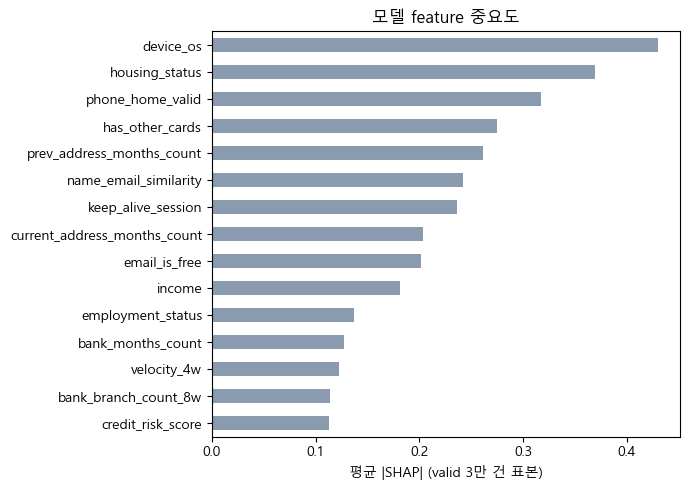

In [15]:
ax = imp.head(15)[::-1].plot(kind="barh", figsize=(7, 5), color="#8a9bb0")
ax.set_xlabel("평균 |SHAP| (valid 3만 건 표본)")
ax.set_title("모델 feature 중요도")
plt.tight_layout()
plt.savefig("../images/model_importance.png", dpi=150)
plt.show()

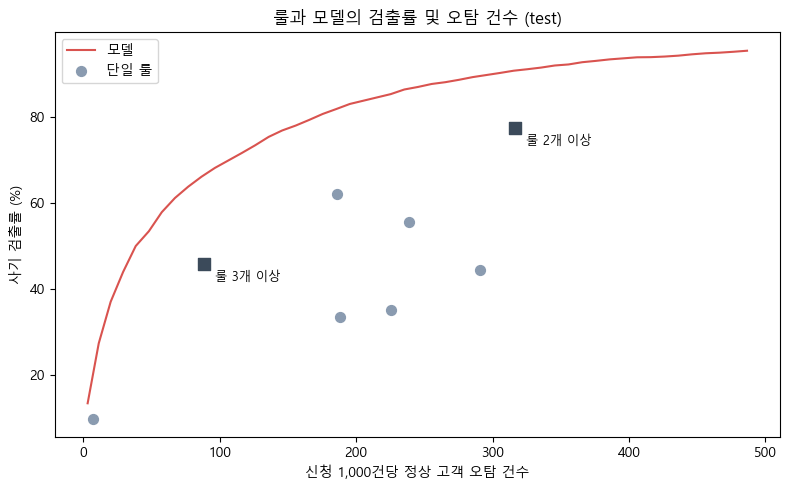

In [16]:
y_arr = y_test.values == 1
grid = np.linspace(0.005, 0.5, 50)

fp_list, rec_list = [], []
for r in grid:
    flag = p_test >= np.quantile(p_test, 1 - r)
    fp_list.append((flag & ~y_arr).sum() / len(y_arr) * 1000)
    rec_list.append((flag & y_arr).sum() / y_arr.sum())

test_single = pd.DataFrame({k: eval_rule(test, f(test)) for k, f in rules.items()}).T

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fp_list, np.array(rec_list) * 100, color="#d9534f", label="모델")
ax.scatter(test_single["fp_per_1000"], test_single["recall"] * 100,
           color="#8a9bb0", s=50, label="단일 룰")

for k in ["2개 이상", "3개 이상"]:
    row = test_cmp.loc[f"룰 {k}"]
    ax.scatter(row["fp_per_1000"], row["recall"] * 100, color="#3b4a5a", s=70, marker="s")
    ax.annotate(f"룰 {k}", (row["fp_per_1000"], row["recall"] * 100),
                textcoords="offset points", xytext=(8, -12), fontsize=9)

ax.set_xlabel("신청 1,000건당 정상 고객 오탐 건수")
ax.set_ylabel("사기 검출률 (%)")
ax.set_title("룰과 모델의 검출률 및 오탐 건수 (test)")
ax.legend()
plt.tight_layout()
plt.savefig("../images/model_vs_rule.png", dpi=150)
plt.show()

In [18]:
scores = pd.concat([
    pd.DataFrame({
        "split": "valid",
        "month": valid["month"].values,
        "fraud_bool": y_valid.values,
        "age_50plus": (valid["customer_age"] >= 50).values,
        "rule_hits": hits_v.values,
        "score": p_valid,
    }),
    pd.DataFrame({
        "split": "test",
        "month": test["month"].values,
        "fraud_bool": y_test.values,
        "age_50plus": (test["customer_age"] >= 50).values,
        "rule_hits": hits_t.values,
        "score": p_test,
    }),
])
scores.to_parquet("../results/scores.parquet", index=False)

joblib.dump(
    {"model": model, "cat_types": cat_types, "sentinel_cols": sentinel_cols,
     "drop_cols": drop_cols, "cutoffs": cutoffs},
    "../data/processed/model_bundle.joblib",
)

['../data/processed/model_bundle.joblib']